# DATA3320 Week 8 — Class Demo 1
## Introduction to Machine Learning with Health Data

**Primary emphasis: concepts and explanation first; code and examples second**

> **Teaching dataset:** `Wk8_ClassDemo_health_data.csv` contains **65,000 fully synthetic records** created for this class. It contains no real patient information. Relationships in this dataset are artificial teaching relationships and must not be interpreted as clinical findings or medical advice.

### Learning outcomes
By the end of this class, students should be able to:

1. explain machine learning in plain language;
2. distinguish traditional rule-based programming from learning from examples;
3. describe observations, features, targets, algorithms, models, training, and prediction;
4. distinguish supervised learning from the broader idea of machine learning;
5. distinguish regression from classification by examining the target;
6. explain why understanding and inspecting data comes before modelling;
7. identify identifiers, numerical variables, and categorical variables;
8. explain association versus causation;
9. explain the basic idea of target leakage;
10. prepare feature data `X` and target data `y` for the next class.

### Today's guiding question

> **How can a computer use historical examples to learn a pattern and make a prediction for a new case?**


## 📚 Week 8 Learning Resources

This notebook supports the Week 8 learning materials. Review the resources below before and after completing this class demo.

#### Lecture 13 – Introduction to Machine Learning
- [Recording](https://nait.video.yuja.com/V/Video?v=1347406&node=7565709&a=146227298)
- [Lecture 13 Presentation](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=25805&type=content&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551444)

- [Lecture 13-14 Intro ML Notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture13-14_Intro_ML.ipynb)

#### Lecture 13 Workbook
- [Workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture13_workbook.ipynb)
- [Solution](https://colab.research.google.com/drive/1p6AKV58F5crZeUJfqTzgEY77DLPEHZKa?usp=sharing)


### 🧪 Assignment

#### Machine Learning Assignment 1
- [Assignment Submission Folder](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551188)
- [Assignment Walkthrough Recording](https://nait.video.yuja.com/V/Video?v=1347404&node=7565707&a=124245085)

### 📖 Required Reading

#### Machine Learning with Python
- [O'Reilly Online Book](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)

Read:

- Chapter 1 — Let's Discuss Learning
- Chapter 2 — Some Technical Background




<details>
<summary>📝 Note</summary>

**0–5 min | Set expectations.** Tell students explicitly that today's goal is *not* to build an impressive model. The goal is to understand the language and logic of machine learning well enough that next class's modelling code makes sense. Keep returning to the guiding question throughout the class.

</details>


## 1. Start with the Big Picture: What Does “Learning” Mean?

The word **learning** can make machine learning sound mysterious. For this course, we can start with a practical definition:

> **Machine learning is a way for a computer to learn useful patterns from examples and use those patterns to make predictions about new examples.**

The computer does not “understand” a health record in the way a person does. Instead, an algorithm examines many examples, looks for mathematical relationships between input variables and an outcome, and represents those relationships in a **model**.

A simple mental model is:

**Historical examples → learning algorithm → fitted model → prediction for a new example**

### A familiar human analogy

Suppose you have looked at hundreds of used-car listings. After a while, you may form expectations about price based on age, mileage, make, condition, and other information. You may not consciously write a precise formula, but past examples influence your estimate for a new vehicle.

Machine learning follows a related *pattern-from-examples* idea, except the learning process is mathematical and computational.

### What machine learning is not

Machine learning is not automatically:

- proof that one variable **causes** another;
- a guarantee that every prediction is correct;
- a substitute for understanding the data;
- a reason to include every available column;
- “artificial intelligence magic.”

A useful model can still make errors. An important part of machine learning is therefore learning **how to evaluate predictions**, which we will begin in Class Demo 2.


### The Complete Machine-Learning Lifecycle

It is useful to see machine learning as a **process**, not as one Python command.

A practical supervised-learning lifecycle is:

1. **Define the prediction problem**  
   Decide what decision or prediction is needed and what one observation represents.
2. **Collect historical data**  
   Gather examples containing information that was available and an outcome that is already known.
3. **Understand and prepare the data**  
   Inspect data types, missing values, duplicates, suspicious values, identifiers, and categorical variables.
4. **Define features and target**  
   Decide which columns are inputs and which outcome is being predicted.
5. **Split historical data for learning and evaluation**  
   Keep some observations away from the training process so the fitted model can later be tested on held-out examples.
6. **Train a model**  
   Apply an algorithm to the training examples so it can estimate a predictive relationship.
7. **Evaluate predictions**  
   Compare predictions with known held-out targets and measure prediction error.
8. **Use the model on new observations**  
   Provide feature values for a case where the target is unknown and obtain a prediction.
9. **Monitor and revisit the model**  
   A model may need to be reviewed when data, behaviour, or the prediction problem changes.

### Where are we today?

Class Demo 1 concentrates on the **front half** of the lifecycle: understanding the problem, understanding the data, and defining features and target. Class Demo 2 moves into splitting data, training a model, predicting, and evaluating.


<details>
<summary>📝 Note</summary>

**Lifecycle teaching move:** Put the lifecycle on the board and leave it visible. At each major transition ask, “Where are we in the ML lifecycle right now?” Students should understand that `.fit()` is only one step in a much larger process.

**5–15 min | Discussion.** Ask, “Where do you already make predictions from past examples?” Accept everyday examples such as estimating travel time, restaurant wait time, sales, or prices. Then connect those examples back to *past examples → pattern → new prediction*. Avoid code during this segment.

</details>


### 🧠 Check-In 1

In your own words:

1. What does it mean for a machine-learning system to “learn” from data?
2. Does learning a useful predictive pattern automatically prove cause and effect?

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 1 — Expected Answer</summary>

1. A strong answer: the algorithm examines historical examples and estimates mathematical relationships that can be used to predict an outcome for new examples.
2. **No.** A predictive association does not by itself establish causation.

</details>


## 2. Traditional Programming vs. Machine Learning

It helps to contrast machine learning with traditional rule-based programming.

### Traditional rule-based approach

A programmer specifies the rules that transform inputs into an output.

**Data + human-written rules → output**

For example, a program might contain an explicit rule:

```text
if order_total >= 50:
    shipping_fee = 0
else:
    shipping_fee = 8
```

The programmer already knows the rule and instructs the computer exactly what to do.

### Supervised machine-learning approach

Sometimes the relationship is too complicated to express as a small set of hand-written rules. Instead, we provide historical examples where the desired answer is already known.

**Historical inputs + known answers → learning algorithm → model**

The model can then be used as:

**New inputs + fitted model → predicted answer**

### Why historical examples matter

During supervised learning, the known historical answers provide feedback about what the algorithm is trying to learn. If we want to predict annual healthcare cost, the historical dataset must contain examples where healthcare cost is already known.

That does **not** mean the target will be known for a future case. The target is known in historical examples so the algorithm can learn and so we can later evaluate predictions.


<details>
<summary>📝 Note</summary>

**15–25 min.** Draw the two flows on the board. Spend time on the difference between *rules supplied by a programmer* and *patterns estimated from labelled examples*. Ask students where the “known answer” appears in supervised learning.

</details>


### 🧠 Check-In 2

Consider these two situations:

**A.** A payroll program calculates overtime using a rule explicitly entered by a programmer.  
**B.** A model studies thousands of previous transactions and learns patterns associated with future sales.

Which is closer to traditional rule-based programming, and which is closer to machine learning? Why?

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 2 — Expected Answer</summary>

A is closer to **traditional rule-based programming** because a human specifies the calculation rule. B is closer to **machine learning** because the system estimates a predictive relationship from historical examples.

</details>


## 3. The Vocabulary We Need Before We Write Code

The same small set of terms appears throughout supervised machine learning.

### Observation

An **observation** is one case or example, usually represented by one row of a dataset.

In our synthetic dataset, one row represents one synthetic health record.

### Feature

A **feature** is an input variable that may be used to make a prediction. Examples in our dataset include:

- `age`
- `bmi`
- `systolic_bp`
- `exercise_hours`
- `sleep_hours`

Features are information we intend to provide to the model when asking for a prediction.

### Target

The **target** is the outcome we want the model to predict.

For today's problem:

> **Target = `health_cost`**

### Algorithm

An **algorithm** is a learning method. In the next class, one algorithm we will use is linear regression.

### Model

A **model** is the fitted result after an algorithm learns from a particular training dataset.

This distinction is important:

> **Algorithm = learning method**  
> **Model = learned result**

The same algorithm can produce different fitted models when it learns from different data.

### Training

**Training** or **fitting** is the process in which the algorithm uses historical examples to estimate a model.

### Prediction

A **prediction** is the model's estimated target value for a set of feature values.


### One Worked Conceptual Example

Imagine one historical synthetic record:

| Variable | Value | Role in our prediction problem |
|---|---:|---|
| age | 52 | feature |
| BMI | 29.4 | feature |
| systolic BP | 132 | feature |
| exercise hours | 2.5 | feature |
| sleep hours | 6.5 | feature |
| annual healthcare cost | $7,200 | **target** |

Because this is a **historical** example, we already know the target: $7,200.

Later, suppose we receive a new record containing only the feature information. The healthcare cost is not yet known. A fitted model can use the feature values to produce a **predicted healthcare cost**.

A prediction is an estimate. It may be close to or far from the eventual actual value. That is why evaluation matters.


### Training Data vs. New, Unseen Data

A crucial idea is that **historical learning data and future prediction data serve different purposes**.

#### During learning

For historical examples, we have both:

**features + known target**

The known target allows the algorithm to learn what kinds of feature patterns tend to be associated with different outcomes.

#### During prediction

For a genuinely new observation, we have:

**features + unknown target**

The unknown target is exactly what the fitted model is being asked to estimate.

```text
Historical examples
features + known target
          ↓
       TRAIN
          ↓
        model

New observation
features + unknown target
          ↓
        model
          ↓
      prediction
```

This distinction explains why the target appears in our historical dataset even though, in real prediction, the target is not yet known.


<details>
<summary>📝 Note</summary>

**Concrete demonstration:** Display one row from the dataset and physically cover the `health_cost` column. Ask: “If this were a new observation arriving tomorrow, what information would the model receive, and what value would we be asking it to estimate?” This sets up the train/test logic for Class Demo 2.

**25–40 min.** Slow down here. Ask students to point to an observation, then a feature, then the target. Ask: “At prediction time, which value do we *not* know?” Also ask why algorithm and model are not synonyms.

</details>


### 🧠 Check-In 3

Suppose we want to predict `health_cost`.

1. What does one **observation** represent?
2. Give three possible **features**.
3. What is the **target**?
4. What is the difference between an algorithm and a fitted model?

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 3 — Expected Answer</summary>

1. One observation is one synthetic record/row.
2. Examples include `age`, `bmi`, `systolic_bp`, `exercise_hours`, and `sleep_hours`.
3. The target is `health_cost`.
4. An algorithm is the learning method; the fitted model is the relationship learned from a specific training dataset.

</details>


## 4. Supervised Learning, Regression, and Classification

### Supervised learning

Today's examples are **supervised learning** because each historical training example contains a known target.

A useful way to remember the idea is:

> Historical example = features **plus** known target

The known target provides the outcome that the algorithm is trying to learn to predict.

### Two common supervised-learning problem types

#### Regression

Use **regression** when the target is a numerical quantity.

Examples:

- annual healthcare cost
- house price
- sales revenue
- delivery time
- temperature

A regression model might predict a value such as `$6,850`.

#### Classification

Use **classification** when the target is a category or class.

Examples:

- Yes / No
- churn / no churn
- approve / decline
- low / medium / high

A classification model might predict a label such as `Yes`.

### The most important question

Do **not** decide regression versus classification by looking at the features. Ask:

> **What type of answer is the model expected to produce?**

The same input features could be used in either type of problem if the target changes.


### Predictions Are Estimates: Error Is Normal

A beginner may expect a useful model to predict every target exactly. That is not how most predictive models work.

For one observation:

- **Actual value** = the outcome that really occurred or is recorded.
- **Predicted value** = the model's estimate.
- **Prediction error** = the difference between actual and predicted values.

For example, if an actual synthetic cost were `$7,200` and a model predicted `$6,900`, the prediction would not be exact. That does not automatically make the model useless. We need a consistent way to examine errors **across many held-out observations**.

Class Demo 2 introduces measures such as MAE, RMSE, and R². For now, the important idea is:

> **A model should be judged by how usefully it generalizes, not by whether every prediction is perfect.**


<details>
<summary>📝 Note</summary>

**Misconception check:** Ask, “If actual and predicted are different, did Python fail?” Expected response: no. The model produced an estimate; evaluation tells us whether the errors are acceptable for the problem. Avoid teaching metric formulas here.

</details>


### Underfitting, Generalization, and Overfitting

Three ideas help us think about how well a model has learned.

#### Underfitting

A model **underfits** when it is too limited to capture enough useful structure in the data. It performs poorly even on the kinds of examples from which it is supposed to learn.

#### Good generalization

The goal is not memorization. The goal is to learn patterns that remain useful for **new observations** the model did not train on. This ability is called **generalization**.

#### Overfitting

A model **overfits** when it learns the training examples too specifically, including details or noise that do not generalize well. Training performance may look extremely strong while performance on new data is weaker.

A simple intuition is:

```text
Underfitting        Useful generalization        Overfitting
too simple     ←        useful pattern       →   too specific
```

We will not diagnose these formally today. Class Demo 2 will compare training and test performance so that overfitting becomes visible in the output.


<details>
<summary>📝 Note</summary>

**Keep this conceptual.** Do not introduce decision-tree mechanics here. Ask: “Is our goal to remember the 65,000 historical rows or to learn something useful for a new row?” Expected answer: learn a pattern that generalizes.

**40–50 min.** Do several oral examples before the formal Check-In. If students hesitate, keep asking “What must the model output?” rather than discussing algorithms.

</details>


### 🧠 Check-In 4

Identify each problem as **regression** or **classification**:

1. Predict annual healthcare cost.
2. Predict readmission: Yes or No.
3. Predict systolic blood pressure.
4. Predict a risk group: Low, Medium, or High.
5. Predict length of stay in days.

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 4 — Expected Answer</summary>

1. Regression
2. Classification
3. Regression
4. Classification
5. Regression

The decision is based on the **target/output type**.

</details>


## 5. Meet the Synthetic Health Dataset

Now that the concepts are established, we can use Python as a **tool for seeing the ideas in data**.

Our dataset has 65,000 synthetic observations. Before training any model, we need to understand what the rows and columns represent.

### Dataset dictionary

| Column | Meaning in this teaching dataset | Initial role |
|---|---|---|
| `patient_id` | synthetic record identifier | identifier |
| `age` | age in years | candidate numerical feature |
| `bmi` | body mass index | candidate numerical feature |
| `systolic_bp` | synthetic systolic blood pressure | candidate numerical feature |
| `diastolic_bp` | synthetic diastolic blood pressure | candidate numerical feature |
| `resting_hr` | synthetic resting heart rate | candidate numerical feature |
| `exercise_hours` | weekly exercise hours | candidate numerical feature |
| `sleep_hours` | average nightly sleep hours | candidate numerical feature |
| `smoker` | synthetic Yes/No indicator | candidate categorical feature |
| `cholesterol` | synthetic total cholesterol | candidate numerical feature |
| `health_cost` | synthetic annual healthcare cost | **target** |

The word **candidate** is important. A variable being present in a dataset does not automatically mean we should put it into a model.


In [83]:
import pandas as pd
import matplotlib.pyplot as plt

health = pd.read_csv('Wk8_ClassDemo_health_data.csv')
health.head()

,patient_id,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol,health_cost
0,P000001,51,23.1,118,68,75,2.1,7.6,No,211,6288
1,P000002,31,19.5,88,75,78,6.9,6.6,No,141,4930
2,P000003,22,24.2,112,67,74,2.2,5.9,No,185,4877
3,P000004,23,31.1,88,57,82,4.1,7.7,No,144,5148
4,P000005,49,31.3,132,60,66,4.1,7.4,Yes,217,6505


<details>
<summary>📝 Note</summary>

**50–58 min.** Before running the cell, ask what students expect one row to represent. After running it, point to one row and ask students to identify features, identifier, and target. The code itself is not the teaching point.

</details>


## 6. Why Inspect Data Before Modelling?

A model learns from the information that we provide. The algorithm does not automatically know whether a column is meaningful or whether a value is suspicious.

A dangerous modelling problem is not always a Python error. Sometimes the code runs perfectly but the analysis is conceptually wrong.

Before modelling, ask four questions:

### 1. Structure
How many observations and variables do we have?

### 2. Meaning
What does each column represent in the real problem?

### 3. Type
Is a variable numerical, categorical, an identifier, a date, free text, or something else?

### 4. Quality
Are values missing, duplicated, inconsistent, or outside expected ranges?

For a large dataset, we normally inspect a small number of rows rather than displaying all observations.


In [86]:
print('Rows and columns:', health.shape)
print()
health.info()

Rows and columns: (65000, 11)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65000 entries, 0 to 64999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      65000 non-null  object 
 1   age             65000 non-null  int64  
 2   bmi             65000 non-null  float64
 3   systolic_bp     65000 non-null  int64  
 4   diastolic_bp    65000 non-null  int64  
 5   resting_hr      65000 non-null  int64  
 6   exercise_hours  65000 non-null  float64
 7   sleep_hours     65000 non-null  float64
 8   smoker          65000 non-null  object 
 9   cholesterol     65000 non-null  int64  
 10  health_cost     65000 non-null  int64  
dtypes: float64(3), int64(6), object(2)
memory usage: 5.5+ MB


In [87]:
health.isna().sum()

patient_id        0
age               0
bmi               0
systolic_bp       0
diastolic_bp      0
resting_hr        0
exercise_hours    0
sleep_hours       0
smoker            0
cholesterol       0
health_cost       0
dtype: int64

In [88]:
health.describe().round(2)

,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,cholesterol,health_cost
count,65000.00,65000.00,65000.00,65000.00,65000.00,65000.00,65000.00,65000.00,65000.00
mean,49.24,27.54,114.75,69.84,75.61,2.98,7.01,180.09,6350.11
std,18.19,5.13,13.06,7.97,7.86,2.09,1.05,32.37,1447.77
min,18.00,16.50,88.00,52.00,45.00,0.00,3.50,105.00,1301.00
25%,34.00,24.00,105.00,64.00,70.00,1.40,6.30,158.00,5361.00
50%,49.00,27.50,115.00,70.00,76.00,2.50,7.00,180.00,6327.00
75%,65.00,31.00,124.00,75.00,81.00,4.00,7.70,202.00,7326.00
max,80.00,46.00,168.00,103.00,107.00,12.00,10.00,312.00,13337.00


### 🧠 Check-In 5

Use the outputs above.

1. How many observations and columns are present?
2. Which columns are stored as text/object?
3. Does the generated dataset contain missing values?
4. Why is `patient_id` different from a feature such as `age`?

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 5 — Expected Answer</summary>

1. **65,000 observations and 11 columns.**
2. `patient_id` and `smoker` are stored as object/text.
3. No missing values are present in this generated dataset.
4. `patient_id` is intended only to identify a row. Its value has no intended predictive health meaning, while `age` represents a measured characteristic.

</details>


<details>
<summary>📝 Note</summary>

**58–72 min.** Have students find the evidence in the output rather than simply accepting the answers. Emphasize that text is not automatically “bad”: `smoker` is meaningful categorical information, while `patient_id` is an identifier.

</details>


## 7. Exploring Relationships Before Modelling

Exploratory analysis helps us understand what information may be available for a model to learn.

### Positive and negative association

A **positive association** means that larger values of one variable tend to occur with larger values of another.

A **negative association** means that larger values of one variable tend to occur with smaller values of another.

### Correlation

Pearson correlation summarizes the strength and direction of a **linear** relationship using a value between -1 and +1.

- near **+1**: strong positive linear association
- near **0**: weak linear association
- near **-1**: strong negative linear association

Correlation has important limits:

- it focuses on linear association;
- a low correlation does not prove “no relationship”;
- correlation does **not** establish causation;
- in this class dataset, relationships are synthetic by design.

The goal is not to discover medical facts. The goal is to learn how exploratory evidence supports modelling decisions.


In [93]:
numeric_cols = [
    'age', 'bmi', 'systolic_bp', 'diastolic_bp',
    'resting_hr', 'exercise_hours', 'sleep_hours',
    'cholesterol', 'health_cost'
]
health[numeric_cols].corr().round(2)

,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,cholesterol,health_cost
age,1.00,0.00,0.66,0.55,0.00,0.00,0.00,0.58,0.48
bmi,0.00,1.00,0.30,0.24,0.16,0.00,0.01,0.21,0.45
systolic_bp,0.66,0.30,1.00,0.43,0.08,-0.10,-0.00,0.44,0.50
diastolic_bp,0.55,0.24,0.43,1.00,0.04,0.00,0.00,0.36,0.37
resting_hr,0.00,0.16,0.08,0.04,1.00,-0.26,-0.00,0.03,0.11
exercise_hours,0.00,0.00,-0.10,0.00,-0.26,1.00,-0.00,0.00,-0.13
sleep_hours,0.00,0.01,-0.00,0.00,-0.00,-0.00,1.00,-0.00,-0.05
cholesterol,0.58,0.21,0.44,0.36,0.03,0.00,-0.00,1.00,0.45
health_cost,0.48,0.45,0.50,0.37,0.11,-0.13,-0.05,0.45,1.00


### 🧠 Check-In 6

Look at the `health_cost` column of the correlation table.

1. Which numerical feature has the largest absolute correlation with `health_cost`?
2. What does the sign of that correlation describe?
3. Can we conclude that the feature **causes** changes in healthcare cost?

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 6 — Expected Answer</summary>

1. Students should identify the feature with the largest absolute value in the displayed `health_cost` correlations.
2. A positive sign indicates the variables tend to move in the same direction; a negative sign indicates they tend to move in opposite directions.
3. **No.** Correlation describes association, not causation.

</details>


### Why sample points for a plot?

The full dataset contains 65,000 points. A scatter plot containing every point may become visually crowded because many observations overlap.

For visualization, we can draw a reproducible random sample of 2,500 rows. This is a **display decision**, not a change to the modelling dataset.

> We can analyze a large dataset while displaying a smaller, readable visual sample.


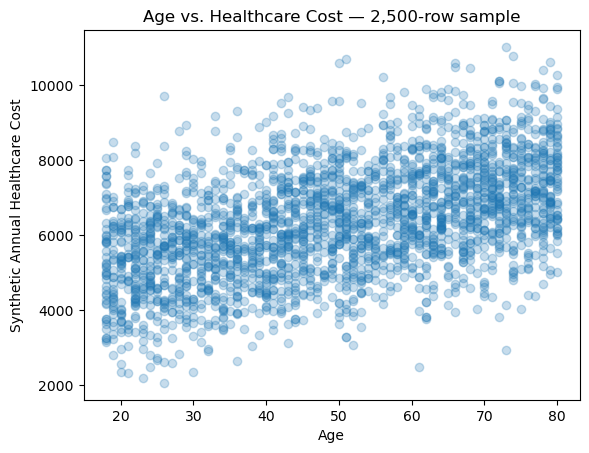

In [97]:
plot_sample = health.sample(n=2500, random_state=42)

plt.scatter(plot_sample['age'], plot_sample['health_cost'], alpha=0.25)
plt.xlabel('Age')
plt.ylabel('Synthetic Annual Healthcare Cost')
plt.title('Age vs. Healthcare Cost — 2,500-row sample')
plt.show()

### ✏️ Your Turn — Read a Relationship Visually

Create a scatter plot of **BMI vs. healthcare cost** using `plot_sample`.

Before running any code, predict what kind of pattern you expect to see. After plotting, describe the pattern using the word **association**, not **causation**.

In [99]:
# Your code here


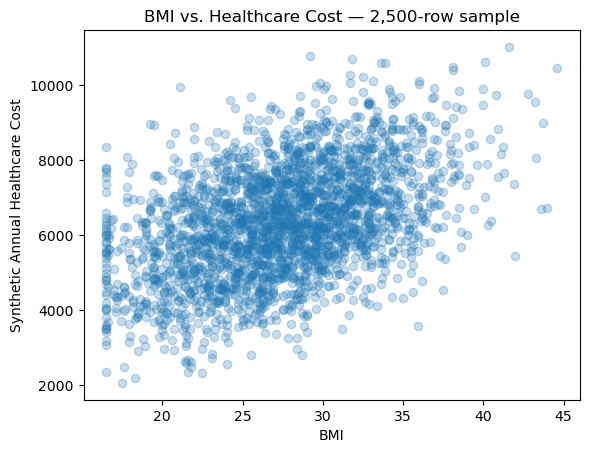

In [100]:
# SOLUTION — reveal after students try
plt.scatter(plot_sample['bmi'], plot_sample['health_cost'], alpha=0.25)
plt.xlabel('BMI')
plt.ylabel('Synthetic Annual Healthcare Cost')
plt.title('BMI vs. Healthcare Cost — 2,500-row sample')
plt.show()

<details>
<summary>✅ Expected interpretation</summary>

A good answer describes the visible direction and strength of the association in the plotted synthetic data without claiming that BMI causes healthcare cost. Students should also recognize that the plot is based on a 2,500-row visualization sample, while the full dataset still contains 65,000 rows.

</details>


<details>
<summary>📝 Note</summary>

**72–88 min.** Explanation comes first. Ask for a prediction before running each graph. After the graph, focus on descriptive language: direction, strength, spread, and outliers. Correct causal wording immediately.

</details>


## 8. Data Quality, Useful Features, and Target Leakage

Before using a column as a feature, ask whether it makes sense for the intended prediction.

### Identifiers

`patient_id` identifies observations. It was generated to distinguish rows. Its code-like value does not represent an intended health measurement. Including arbitrary identifiers can encourage a model to learn meaningless patterns.

### Missing values

Missing data require thought. We need to know whether values are missing randomly, because of a process, or because a measurement was not available. Handling missing data is a modelling decision, not merely a cleaning command.

### Duplicates

Duplicate rows can change the apparent distribution of a dataset. They can also be especially problematic if nearly identical cases are placed in both training and test sets.

### Suspicious or impossible values

A numeric column being stored correctly does not guarantee that every value is plausible. Domain understanding still matters.

### Target leakage

**Target leakage** occurs when the feature information contains the answer, a proxy for the answer, or information that would not really be available when the prediction must be made.

#### Simple leakage example

Suppose you want to predict a student's final grade using:

- assignment average
- quiz average
- attendance
- **final grade**

The final feature gives the model the answer. Performance could look excellent, but the model has not learned a useful prediction problem.

If we put `health_cost` inside `X` while also using `health_cost` as our target `y`, we create the same basic problem.


### What Makes a Feature Potentially Useful?

A feature is not useful merely because it appears as a column in a spreadsheet. Before using a variable, ask whether it passes several practical tests.

#### 1. Available at prediction time
Would this information really be known when the prediction is needed? If not, the model cannot rely on it in real use.

#### 2. Relevant to the prediction problem
There should be a reasonable reason to consider the variable as information for this predictive task. Availability alone is not enough.

#### 3. Represented consistently
Values should have a consistent meaning and format. For example, a category should not be written in several inconsistent ways.

#### 4. Reasonably reliable
If a variable is dominated by measurement or recording problems, the model may learn noise rather than useful signal.

#### 5. Free from target leakage
A feature must not reveal the target directly or contain information that would only become available after the outcome occurs.

### Apply the checklist

Consider our columns:

- `age`: meaningful candidate numerical feature
- `bmi`: meaningful candidate numerical feature
- `smoker`: meaningful candidate categorical feature that requires suitable representation
- `patient_id`: useful for identifying records, but not intended as a health feature
- `health_cost`: the target, so it must not also be supplied as a feature

Feature selection is therefore partly a **reasoning task**, not merely a coding task.


<details>
<summary>📝 Note</summary>

**Feature-selection discussion:** Put `age`, `bmi`, `smoker`, `patient_id`, and `health_cost` on the board. For each, ask three questions: “Would we know it at prediction time?”, “Does it have meaningful predictive content?”, and “Does it leak the answer?” Require students to justify each decision.

</details>


In [106]:
quality_check = pd.Series({
    'duplicate_rows': health.duplicated().sum(),
    'minimum_age': health['age'].min(),
    'maximum_age': health['age'].max(),
    'minimum_bmi': health['bmi'].min(),
    'maximum_bmi': health['bmi'].max()
})
quality_check

duplicate_rows     0.0
minimum_age       18.0
maximum_age       80.0
minimum_bmi       16.5
maximum_bmi       46.0
dtype: float64

### 🧠 Check-In 7

For each item, explain whether it should automatically be used as a feature:

1. `patient_id`
2. `age`
3. `smoker`
4. `health_cost`, when `health_cost` is also the prediction target

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 7 — Expected Answer</summary>

1. `patient_id`: generally **no** for this exercise; it is an identifier.
2. `age`: a meaningful candidate numerical feature.
3. `smoker`: a meaningful candidate categorical feature, but it requires appropriate representation before use with the numerical model planned for Class 2.
4. `health_cost`: **no**. It is the target; using it as an input would leak the answer.

</details>


<details>
<summary>📝 Note</summary>

**88–98 min.** Target leakage is the key idea. Use the student-grade analogy before returning to health data. Ask, “Would this information really be available at the moment we need the prediction?”

</details>


## 9. Preparing `X` and `y`: Connecting the Ideas to Python

Now we are ready for a small amount of machine-learning preparation.

A common convention is:

- **`X`** = the feature matrix
- **`y`** = the target vector

### Why is `X` a table?

Each row is an observation and each selected column is a feature.

With 65,000 observations and five selected features, `X` should have shape:

`(65000, 5)`

### Why is `y` a single series?

For every observation, we have one target value: the synthetic annual healthcare cost.

So `y` contains 65,000 values.

### Row alignment matters

The target on a given row must belong to the same observation represented by that row of features. We cannot shuffle `X` independently from `y` and still expect meaningful supervised learning.

### Why start with only numerical features?

We are intentionally starting with five numerical features so that next class can focus on the basic modelling workflow. `smoker` is categorical text. Class Demo 2 will show one way to encode it numerically.

This is a **teaching choice**, not a statement that five features are always best.


In [111]:
features = [
    'age',
    'bmi',
    'systolic_bp',
    'exercise_hours',
    'sleep_hours'
]

X = health[features]
y = health['health_cost']

print('X shape:', X.shape)
print('y shape:', y.shape)
X.head()

X shape: (65000, 5)
y shape: (65000,)


,age,bmi,systolic_bp,exercise_hours,sleep_hours
0,51,23.1,118,2.1,7.6
1,31,19.5,88,6.9,6.6
2,22,24.2,112,2.2,5.9
3,23,31.1,88,4.1,7.7
4,49,31.3,132,4.1,7.4


### 🧠 Check-In 8

Explain each statement in plain language:

1. `X` has five columns.
2. `y` has one value per observation.
3. `health_cost` is not inside `X`.
4. `X` and `y` have the same number of observations.

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 8 — Expected Answer</summary>

1. We selected five input features.
2. Each historical observation has one target healthcare-cost value.
3. `health_cost` is the answer we want to predict, so putting it into the inputs would cause leakage.
4. Every feature row must match its corresponding target value.

</details>


## 10. How to Frame a Good Machine-Learning Question

Before choosing an algorithm, define the problem carefully.

A useful predictive question identifies five things:

### 1. Unit of observation
What does one row represent?

### 2. Target
What exactly do we want to predict?

### 3. Prediction moment
When will we make the prediction?

### 4. Available features
What information would genuinely be known at that moment?

### 5. Problem type
Is the target numerical or categorical?

### Example

> **Question:** Can we predict synthetic annual healthcare cost from information available in each synthetic health record?

- Unit of observation: one synthetic record
- Target: `health_cost`
- Candidate features: age, BMI, systolic BP, exercise, sleep, etc.
- Problem type: regression

Good problem framing usually matters more than choosing a complicated algorithm too early.


### 👥 Pair Activity — Design Two Prediction Problems

Create:

1. **one regression question**, and
2. **one classification question**.

For each question, state:

- the unit of observation;
- the target;
- two possible features;
- why the problem is regression or classification.


<details>
<summary>✅ Pair Activity — Expected Answer Structure</summary>

There is no single correct scenario. A complete answer should name a clear unit of observation, a specific target, at least two plausible features available at prediction time, and correctly determine regression/classification from the target type.

</details>


<details>
<summary>📝 Note</summary>

**98–106 min.** Give pairs 4–5 minutes, then ask for one regression and one classification example. Prioritize clear target definition over sophisticated examples.

</details>


## 11. Class 1 Summary: The Story So Far

The most important ideas from today are conceptual:

1. **Machine learning learns predictive patterns from examples.**
2. In supervised learning, historical examples contain **features and a known target**.
3. An **algorithm** is a learning method; a fitted **model** is the result of learning from data.
4. **Regression** predicts numerical targets; **classification** predicts categorical targets.
5. Understanding the dataset comes **before** modelling.
6. A column can be numerical and still be inappropriate as a feature.
7. **Association does not automatically mean causation.**
8. **Target leakage** can make a model appear much better than it really is.
9. `X` contains features; `y` contains the target.
10. Next class, we will learn how to divide historical data into training and test sets, fit a model, make predictions, and evaluate the resulting errors.


### Bridge to Class Demo 2

Today we stop at **features + target**. Next class begins by asking a new question:

> **How can we determine whether a model has learned a useful pattern rather than simply fitting the historical examples?**

The next workflow is:

```text
Features (X) + Target (y)
          ↓
   Train / Test Split
          ↓
      Fit Model
          ↓
 Predict Test Cases
          ↓
 Compare Predicted
 with Known Actuals
          ↓
   Evaluate Error
```

This is why today's distinctions between **feature and target**, **algorithm and model**, and **historical versus new data** matter. They become the foundation for every coding step in Class Demo 2.


<details>
<summary>📝 Note</summary>

**Final bridge:** Point to each item in the diagram and ask students which concepts they already know. Do not teach the mechanics of the split yet. The objective is anticipation: students should understand *why* Class Demo 2 needs a separate evaluation set.

</details>


### 🧠 Check-In 9

Complete the following without looking back:

> In supervised machine learning, an __________ learns from historical examples containing __________ and a known __________. The fitted __________ can then be used to make a __________ for a new example.

*Discuss or write your answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 9 — Expected Answer</summary>

A strong completion is:

> In supervised machine learning, an **algorithm** learns from historical examples containing **features** and a known **target**. The fitted **model** can then be used to make a **prediction** for a new example.

</details>


<details>
<summary>📝 Note</summary>

**106–110 min | Exit ticket.** Ask for the final sentence individually. End by previewing Class Demo 2: train/test split → fit → predict → evaluate. Do not add new theory in the final minutes.

</details>


<details>
<summary>✅ Before Moving to Class Demo 2</summary>

You should be able to explain:

1. What is machine learning?
2. What is supervised learning?
3. What is the difference between a feature and a target?
4. What is the difference between regression and classification?
5. Why do we inspect data before modelling?
6. What is target leakage?
7. Why is `patient_id` not a useful predictive feature?

### 🚀 Next: Class Demo 2

In the next notebook, you will learn how to:

- Split data into training and test sets
- Train a regression model
- Make predictions
- Calculate prediction errors
- Interpret MAE, RMSE, and R²
- Compare models
- Understand generalization and overfitting

</details>
